# DropBlock : régulariser un CNN en supprimant des blocs, pas des pixels

[![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/moncoachdata/MonShotData/blob/main/Machine%20Learning/DropBlock.ipynb)

📖 **Le shot complet** : [Pourquoi le Dropout régularise si mal tes CNN](https://www.monshotdata.com/p/dropblock-regularisation-cnn-pytorch)

---

Dans un CNN, les pixels voisins sont fortement corrélés. Mettre à zéro un pixel isolé (Dropout classique) retire donc très peu d'information : ses voisins la transmettent à la couche suivante. **DropBlock** supprime une **région contiguë** à la place, et force le réseau à apprendre à partir du contexte restant.

Dans ce notebook, tu vas :

1. voir pourquoi un pixel supprimé est « remplacé » par ses voisins ;
2. comparer le masque d'un **Dropout** (pixels isolés) et celui d'un **DropBlock** (blocs de 3×3) ;
3. vérifier ce que fait vraiment le paramètre `p` de `torchvision` ;
4. faire monter le taux de suppression progressivement avec un **planificateur linéaire**.

### Avant de lancer

- **Installation** : PyTorch et torchvision sont déjà installés sur Colab. Sinon : `pip install torch torchvision`. La bibliothèque `dropblock` (section 6) s'installe avec la cellule `%pip` ci-dessous.
- **Les données** : aucune à télécharger. On travaille sur une petite image de synthèse (un « 9 » flou de 16×16 pixels) fabriquée dans le notebook.
- **Durée** : quelques secondes, sur CPU.
- **Les résultats** : les graines sont fixées. Les masques peuvent tout de même différer légèrement d'une version de PyTorch à l'autre ; compare surtout la *forme* des masques (points isolés contre blocs).

## 1. Mise en place

In [1]:
%pip install -q dropblock

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import torch
import torch.nn as nn
from torchvision.ops import DropBlock2d

## 2. Une image de synthèse

Un « 9 » flou de 16×16 pixels, avec des valeurs entre 0 (fond) et 1 (trait). Comme dans une vraie image, deux pixels voisins ont des valeurs proches.

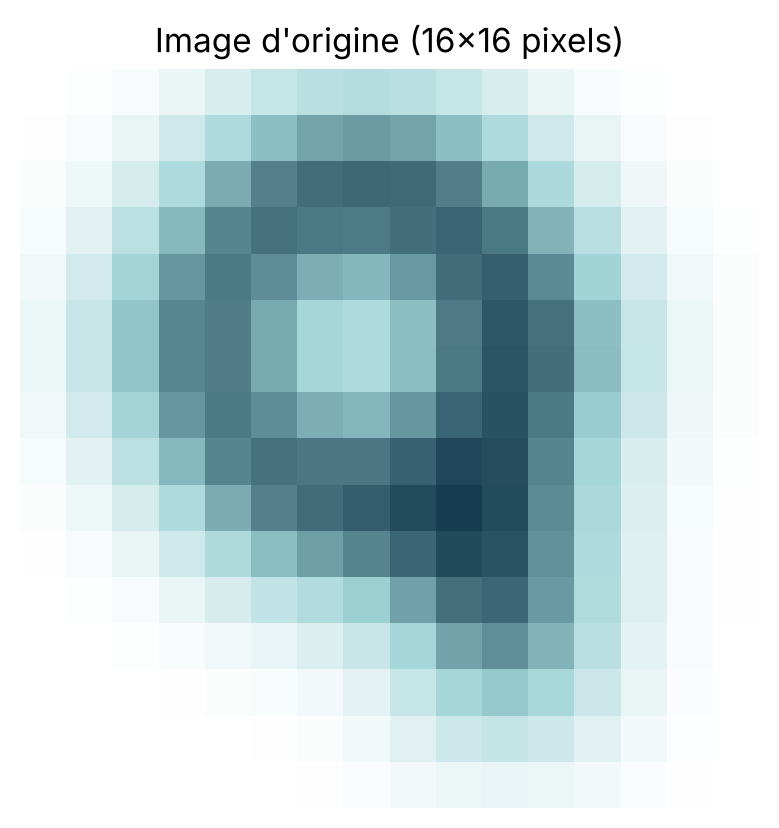

In [2]:
yy, xx = np.mgrid[0:16, 0:16]
img = np.zeros((16, 16))
anneau = np.abs(np.hypot(xx - 7.0, yy - 5.5) - 3.6) < 1.5
queue = (np.abs(xx - 10.2) < 1.4) & (yy >= 5) & (yy <= 13.5)
img[anneau | queue] = 1.0

# flou : deux passes d'un filtre binomial 1D (appliqué en lignes puis en colonnes)
k = np.array([1, 4, 6, 4, 1]) / 16.0
def flou(a):
    a = np.apply_along_axis(lambda r: np.convolve(r, k, mode="same"), 0, a)
    return np.apply_along_axis(lambda r: np.convolve(r, k, mode="same"), 1, a)

img = flou(flou(img))
img = (img - img.min()) / (img.max() - img.min())

cmap = LinearSegmentedColormap.from_list("m", ["#FFFFFF", "#9ED3D6", "#153C4F"])
plt.imshow(img, cmap=cmap, vmin=0, vmax=1)
plt.title("Image d'origine (16×16 pixels)")
plt.axis("off")
plt.show()

## 3. Pourquoi supprimer un pixel isolé change si peu de choses

Prenons un pixel au cœur du trait et mettons-le à zéro, comme le ferait un Dropout. Comparons sa valeur d'origine à la **moyenne de ses 8 voisins**, qui, eux, sont conservés.

In [3]:
# le pixel (ligne 9, colonne 9) est au cœur du trait
r, c = 9, 9
voisinage = img[r - 1:r + 2, c - 1:c + 2]
valeur = voisinage[1, 1]
moyenne_voisins = (voisinage.sum() - valeur) / 8

print(f"Valeur du pixel supprimé : {valeur:.2f}")
print(f"Moyenne de ses 8 voisins : {moyenne_voisins:.2f}")
print(f"Plus petit et plus grand voisin : {np.delete(voisinage.ravel(), 4).min():.2f} et {np.delete(voisinage.ravel(), 4).max():.2f}")

Valeur du pixel supprimé : 1.00
Moyenne de ses 8 voisins : 0.93
Plus petit et plus grand voisin : 0.86 et 0.96


Les voisins portent presque la même information que le pixel supprimé. Après une convolution, la couche suivante « voit » donc quasiment la même chose : le Dropout classique régularise peu.

## 4. Dropout contre DropBlock

On applique les deux sur une image de 16×16 pixels toute à 1 : un pixel est supprimé quand sa valeur devient 0. On règle `p = 0.2` des deux côtés pour comparer à proportion de pixels supprimés comparable.

In [4]:
torch.manual_seed(6)
x = torch.ones(1, 1, 16, 16)  # une « image » de 16×16 pixels

# Dropout classique : chaque pixel est supprimé indépendamment
masque_dropout = (nn.Dropout(p=0.2)(x) == 0)

# DropBlock : on supprime des blocs de 3×3 pixels
masque_dropblock = (DropBlock2d(p=0.2, block_size=3)(x) == 0)

print(f"Dropout   : {masque_dropout.float().mean():.0%} des pixels supprimés")
print(f"DropBlock : {masque_dropblock.float().mean():.0%} des pixels supprimés")

Dropout   : 21% des pixels supprimés
DropBlock : 20% des pixels supprimés


Affichons les deux masques sur notre image (en orange, les pixels mis à zéro) :

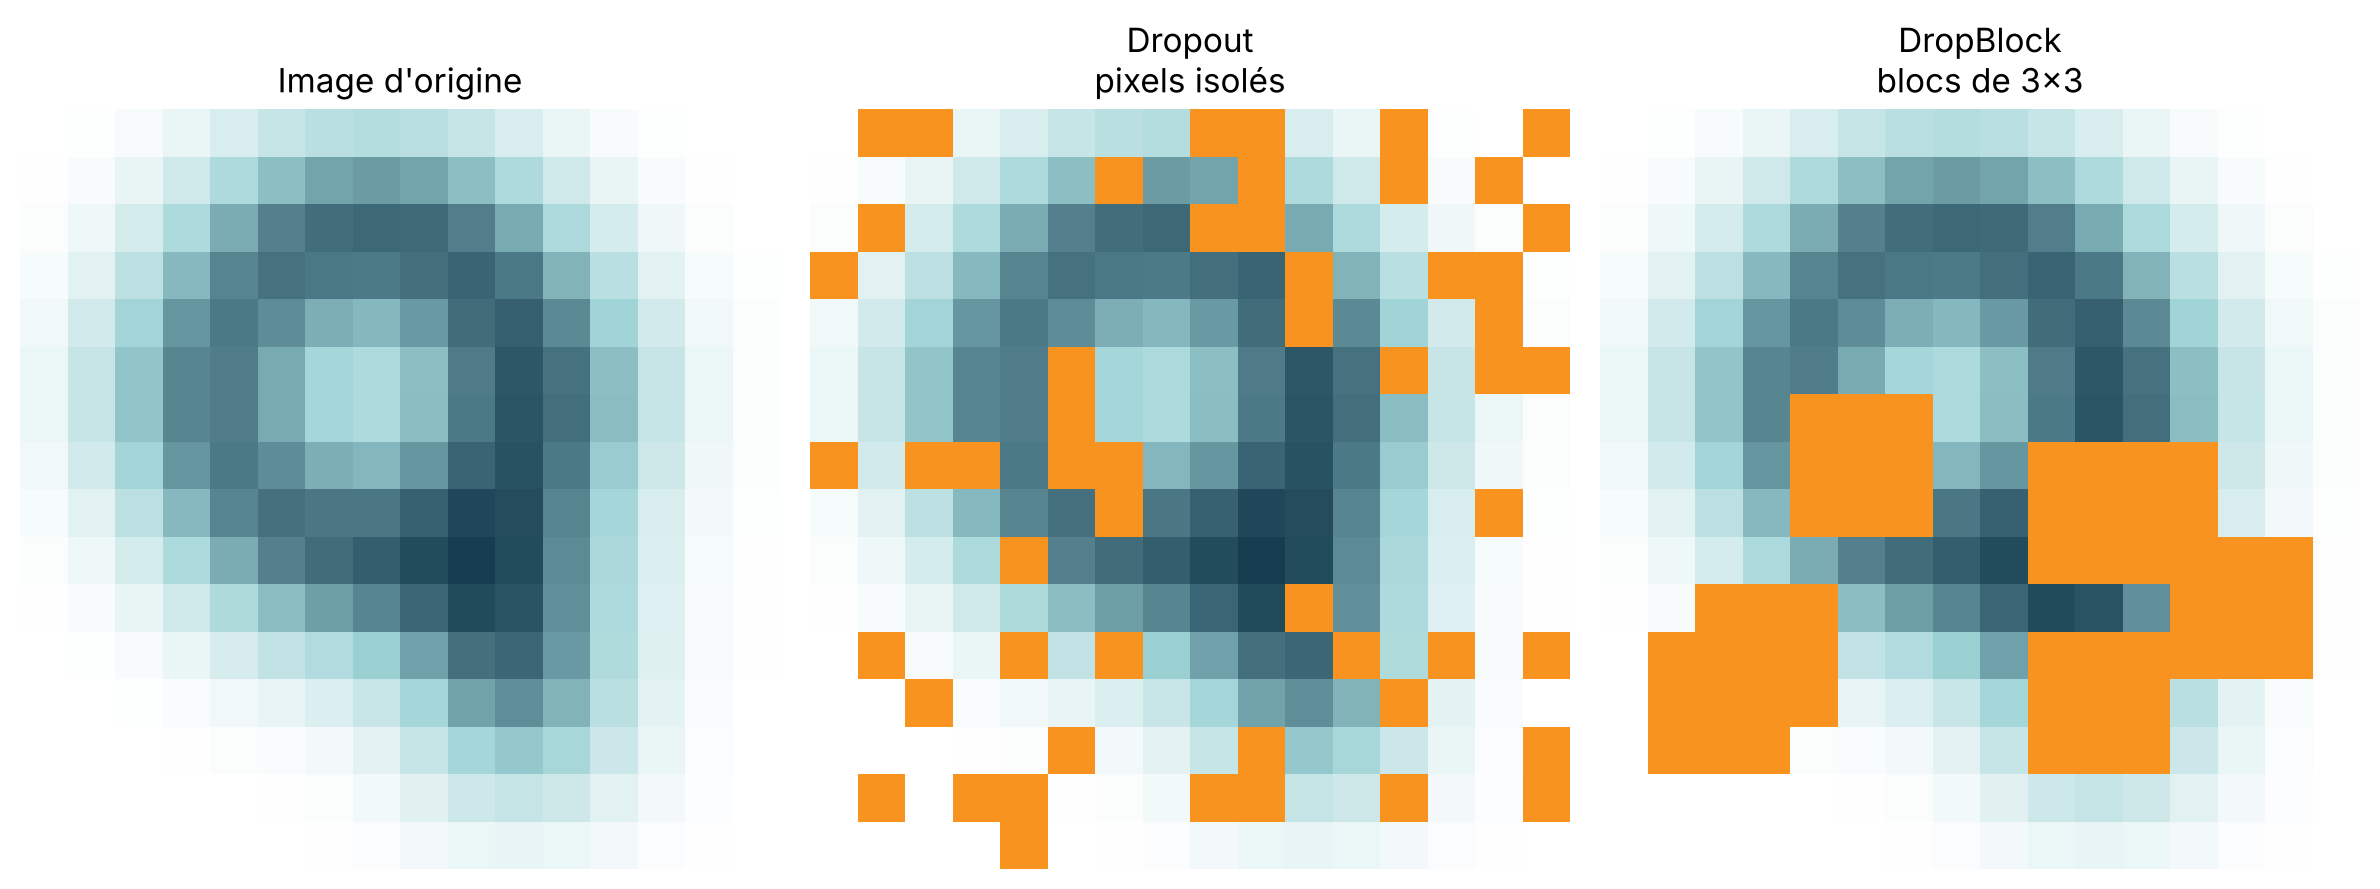

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4.4))
for ax, titre, masque in [
    (axes[0], "Image d'origine", None),
    (axes[1], "Dropout\npixels isolés", masque_dropout[0, 0].numpy()),
    (axes[2], "DropBlock\nblocs de 3×3", masque_dropblock[0, 0].numpy()),
]:
    ax.imshow(img, cmap=cmap, vmin=0, vmax=1)
    if masque is not None:
        surcouche = np.ma.masked_where(~masque, np.ones_like(img))
        ax.imshow(surcouche, cmap=LinearSegmentedColormap.from_list("o", ["#F7931E", "#F7931E"]), vmin=0, vmax=1)
    ax.set_title(titre)
    ax.axis("off")
plt.tight_layout()
plt.show()

Avec le **Dropout**, les pixels supprimés sont isolés : on devine encore le « 9 » grâce aux voisins. Avec **DropBlock**, des zones entières disparaissent : le réseau doit s'appuyer sur le contexte restant.

## 5. Ce que fait DropBlock2d en entraînement et en évaluation

Comme le Dropout, `DropBlock2d` n'agit **qu'en mode entraînement**. En mode évaluation, il laisse tout passer. En entraînement, il **remet à l'échelle** les valeurs conservées (le nombre total de valeurs divisé par le nombre de valeurs conservées) pour garder une activation moyenne stable.

In [6]:
torch.manual_seed(0)
couche = DropBlock2d(p=0.2, block_size=3)
x = torch.ones(1, 1, 16, 16)

couche.train()
y_train = couche(x)
print("Entraînement : part de zéros =", f"{(y_train == 0).float().mean():.0%}")
print("Valeur des pixels conservés  =", y_train[y_train > 0].unique().item())

couche.eval()
y_eval = couche(x)
print("Évaluation   : part de zéros =", f"{(y_eval == 0).float().mean():.0%}")
print("Sortie identique à l'entrée  =", torch.equal(x, y_eval))

Entraînement : part de zéros = 10%
Valeur des pixels conservés  = 1.1082251071929932
Évaluation   : part de zéros = 0%
Sortie identique à l'entrée  = True


## 6. Que signifie `p` ? (torchvision et la bibliothèque `dropblock`)

Dans l'article de recherche, `drop_rate` est la probabilité de supprimer le pixel **central** d'un bloc. Dans `torchvision`, le paramètre s'appelle `p` et fixe **à peu près la proportion de pixels supprimés** : la fonction en déduit elle-même la probabilité `gamma` des pixels centraux (elle dépend de la taille de l'image et de `block_size`).

Vérifions-le sur beaucoup de tirages. La bibliothèque `dropblock`, elle, calcule `gamma = drop_prob / block_size²` (sans tenir compte de la taille de l'image) : les deux conventions ne donnent pas exactement la même proportion.

In [7]:
from dropblock import DropBlock2D

torch.manual_seed(0)
x = torch.ones(2000, 1, 16, 16)   # 2000 images pour avoir une moyenne stable

# gamma de torchvision pour p = 0.2, image 16×16, blocs 3×3
p, H, W, bs = 0.2, 16, 16, 3
gamma_tv = (p * H * W) / (bs**2 * (H - bs + 1) * (W - bs + 1))
print(f"gamma torchvision (p=0.2) : {gamma_tv:.4f} | gamma bibliothèque dropblock : {p / bs**2:.4f}\n")

for p in (0.1, 0.2, 0.3):
    part_tv = (DropBlock2d(p=p, block_size=3)(x) == 0).float().mean().item()
    lib = DropBlock2D(drop_prob=p, block_size=3)
    lib.train()
    part_lib = (lib(x) == 0).float().mean().item()
    print(f"p = {p} -> torchvision : {part_tv:.1%} supprimés | bibliothèque dropblock : {part_lib:.1%} supprimés")

gamma torchvision (p=0.2) : 0.0290 | gamma bibliothèque dropblock : 0.0222

p = 0.1 -> torchvision : 9.7% supprimés | bibliothèque dropblock : 8.8% supprimés
p = 0.2 -> torchvision : 18.4% supprimés | bibliothèque dropblock : 17.4% supprimés
p = 0.3 -> torchvision : 26.1% supprimés | bibliothèque dropblock : 24.5% supprimés


Dans les deux cas, la proportion réellement supprimée est un peu inférieure à `p` (les blocs se chevauchent et sont tronqués sur les bords). Retiens que `p` règle **l'intensité globale** de la régularisation, et que `block_size` règle **la taille des trous**.

## 7. Faire monter le taux progressivement

Les auteurs de DropBlock observent de meilleurs résultats quand le taux de suppression **augmente progressivement** au cours de l'entraînement. La bibliothèque `dropblock` fournit un planificateur linéaire : on appelle `step()` à chaque epoch.

In [8]:
from dropblock import DropBlock2D, LinearScheduler

dropblock = LinearScheduler(
    DropBlock2D(drop_prob=0.0, block_size=3),
    start_value=0.0, stop_value=0.1, nr_steps=5,
)
for epoch in range(5):
    dropblock.step()  # fait monter drop_prob d'un cran à chaque epoch
    print(f"epoch {epoch} : drop_prob = {dropblock.dropblock.drop_prob:.3f}")

epoch 0 : drop_prob = 0.000
epoch 1 : drop_prob = 0.025
epoch 2 : drop_prob = 0.050
epoch 3 : drop_prob = 0.075
epoch 4 : drop_prob = 0.100


Tu peux aussi te passer de la bibliothèque et faire la même chose à la main avec `torchvision` : `DropBlock2d` n'a pas de planificateur intégré, mais son taux `p` est un simple attribut modifiable.

In [9]:
couche = DropBlock2d(p=0.0, block_size=3)
nb_epochs, p_final = 5, 0.1

for epoch in range(nb_epochs):
    couche.p = p_final * epoch / (nb_epochs - 1)   # montée linéaire de 0 à p_final
    print(f"epoch {epoch} : p = {couche.p:.3f}")

epoch 0 : p = 0.000
epoch 1 : p = 0.025
epoch 2 : p = 0.050
epoch 3 : p = 0.075
epoch 4 : p = 0.100


## 8. DropBlock dans un petit CNN

`DropBlock2d` se place après une couche de convolution (et sa fonction d'activation), sur des cartes de caractéristiques de forme `(N, C, H, W)`. Voici un bloc minimal, sans entraînement : on vérifie juste que les formes restent identiques et que la couche se désactive en mode évaluation.

In [10]:
cnn = nn.Sequential(
    nn.Conv2d(3, 16, kernel_size=3, padding=1),
    nn.ReLU(),
    DropBlock2d(p=0.1, block_size=5),
    nn.Conv2d(16, 32, kernel_size=3, padding=1),
    nn.ReLU(),
)

images = torch.randn(4, 3, 32, 32)   # un lot de 4 images en couleur 32×32

cnn.train()
sortie_train = cnn(images)
cnn.eval()
sortie_eval = cnn(images)
print("Forme de sortie :", tuple(sortie_train.shape), "(entraînement) et", tuple(sortie_eval.shape), "(évaluation)")

Forme de sortie : (4, 32, 32, 32) (entraînement) et (4, 32, 32, 32) (évaluation)


## Pour aller plus loin

- L'article de recherche : [DropBlock: A regularization method for convolutional networks](https://arxiv.org/abs/1810.12890). C'est de cet article que viennent les gains mesurés sur ImageNet (+1,33 % par rapport au Dropout, +1,55 % avec le label smoothing).
- Le shot sur la mise à l'échelle du Dropout : [Comment fonctionne vraiment le Dropout ?](https://www.monshotdata.com/p/comment-fonctionne-vraiment-le-dropout)
- Le shot sur une autre technique de régularisation : [Label smoothing : la technique simple pour mieux généraliser](https://www.monshotdata.com/p/label-smoothing-regularisation)
- Le shot de ce notebook : [Pourquoi le Dropout régularise si mal tes CNN](https://www.monshotdata.com/p/dropblock-regularisation-cnn-pytorch)